<a href="https://colab.research.google.com/github/zunairazunaira242006-del/mvj-data-analytics-internship-2026/blob/main/Day_17_Bengaluru_House_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd

df = pd.read_csv('/content/house_prices_bangalore.csv.csv')

print(df.head())
print(df.shape)
print(df.columns)

   area           location  bhk  bath  balcony  parking       furnishing  \
0  2065  Bannerghatta Road    2     3        0        1   Semi-Furnished   
1  1539          Yelahanka    3     1        0        1      Unfurnished   
2  2048  Bannerghatta Road    3     1        2        0   Semi-Furnished   
3  1233      Sarjapur Road    3     2        1        2  Fully-Furnished   
4  2487          Yelahanka    3     3        2        1  Fully-Furnished   

       property_type  age     price  
0  Independent House    3  17280000  
1              Villa    8   9410000  
2  Independent House   10  20300000  
3          Apartment   12   9060000  
4              Villa    4  28660000  
(1000, 10)
Index(['area', 'location', 'bhk', 'bath', 'balcony', 'parking', 'furnishing',
       'property_type', 'age', 'price'],
      dtype='object')


In [5]:
print(df.isnull().sum())

area             0
location         0
bhk              0
bath             0
balcony          0
parking          0
furnishing       0
property_type    0
age              0
price            0
dtype: int64


In [6]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [7]:
df.describe()

,area,bhk,bath,balcony,parking,age,price
count,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,1648.51100,3.082000,2.557000,1.012000,0.965000,8.040000,1.237301e+07
std,487.90919,1.364235,1.415187,0.802808,0.834549,4.338805,5.386504e+06
min,803.00000,1.000000,1.000000,0.000000,0.000000,1.000000,2.850000e+06
25%,1226.75000,2.000000,1.000000,0.000000,0.000000,4.000000,8.405000e+06
50%,1648.00000,3.000000,2.000000,1.000000,1.000000,8.000000,1.132000e+07
75%,2075.25000,4.000000,3.000000,2.000000,2.000000,12.000000,1.543000e+07
max,2499.00000,5.000000,6.000000,2.000000,2.000000,15.000000,3.273000e+07


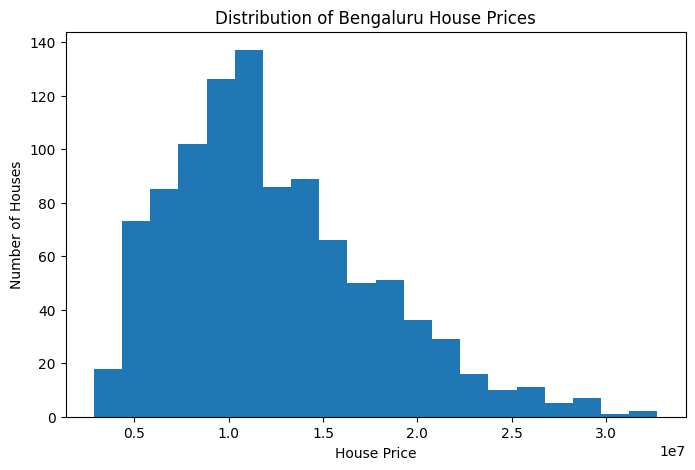

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df['price'], bins=20)
plt.xlabel('House Price')
plt.ylabel('Number of Houses')
plt.title('Distribution of Bengaluru House Prices')
plt.show()

In [9]:
df_encoded = pd.get_dummies(
    df,
    columns=['location', 'furnishing', 'property_type'],
    drop_first=True,
    dtype=int
)

print(df_encoded.head())
print(df_encoded.shape)

   area  bhk  bath  balcony  parking  age     price  location_Banashankari  \
0  2065    2     3        0        1    3  17280000                      0   
1  1539    3     1        0        1    8   9410000                      0   
2  2048    3     1        2        0   10  20300000                      0   
3  1233    3     2        1        2   12   9060000                      0   
4  2487    3     3        2        1    4  28660000                      0   

   location_Bannerghatta Road  location_Bellandur  ...  location_Marathahalli  \
0                           1                   0  ...                      0   
1                           0                   0  ...                      0   
2                           1                   0  ...                      0   
3                           0                   0  ...                      0   
4                           0                   0  ...                      0   

   location_Rajajinagar  location_Sarjapur R

In [10]:
X = df_encoded.drop('price', axis=1)
y = df_encoded['price']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1000, 29)
Target shape: (1000,)


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (800, 29)
Testing data: (200, 29)


In [12]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train[['area']], y_train)

linear_predictions = linear_model.predict(X_test[['area']])

print("Linear Regression completed!")

Linear Regression completed!


In [13]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression RMSE:", linear_rmse)
print("Linear Regression R2 Score:", linear_r2)

Linear Regression RMSE: 3794675.8245371357
Linear Regression R2 Score: 0.5165354035094546


In [14]:
multiple_model = LinearRegression()

multiple_model.fit(X_train, y_train)

multiple_predictions = multiple_model.predict(X_test)

print("Multiple Linear Regression completed!")

Multiple Linear Regression completed!


In [15]:
multiple_rmse = np.sqrt(mean_squared_error(y_test, multiple_predictions))
multiple_r2 = r2_score(y_test, multiple_predictions)

print("Multiple Regression RMSE:", multiple_rmse)
print("Multiple Regression R2 Score:", multiple_r2)

Multiple Regression RMSE: 3309104.22615579
Multiple Regression R2 Score: 0.6323486133362659


In [16]:
comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Multiple Regression'],
    'RMSE': [linear_rmse, multiple_rmse],
    'R2 Score': [linear_r2, multiple_r2]
})

print(comparison)

                 Model          RMSE  R2 Score
0    Linear Regression  3.794676e+06  0.516535
1  Multiple Regression  3.309104e+06  0.632349


In [17]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': multiple_model.coef_
})

coefficients['Absolute_Value'] = coefficients['Coefficient'].abs()

coefficients = coefficients.sort_values(
    by='Absolute_Value',
    ascending=False
)

print(coefficients.head(10))

                            Feature   Coefficient  Absolute_Value
28              property_type_Villa  3.389862e+06    3.389862e+06
26           furnishing_Unfurnished -2.803549e+06    2.803549e+06
27  property_type_Independent House  1.410475e+06    1.410475e+06
25        furnishing_Semi-Furnished -1.361075e+06    1.361075e+06
13                location_JP Nagar  1.171755e+06    1.171755e+06
24               location_Yelahanka -8.330308e+05    8.330308e+05
6             location_Banashankari  7.933886e+05    7.933886e+05
15                location_KR Puram -7.796322e+05    7.796322e+05
8                location_Bellandur -6.616618e+05    6.616618e+05
22             location_Uttarahalli -6.017212e+05    6.017212e+05


In [18]:
comparison.to_csv('Day_17_Regression_Model_Comparison.csv', index=False)

print("Model comparison saved successfully!")

Model comparison saved successfully!


## Day 17 – Bengaluru House Price Prediction

### Objective
To build machine learning regression models to predict Bengaluru house prices using property-related features.

### Dataset
- Total records: 1,000
- Total columns: 10
- Missing values: 0
- Duplicate records: 0

### Models Developed
1. Linear Regression – used area as the input feature.
2. Multiple Linear Regression – used multiple property features, including area, location, BHK, furnishing and property type.

### Model Evaluation

| Model | RMSE | R² Score |
|---|---:|---:|
| Linear Regression | 3,794,676 | 0.5165 |
| Multiple Regression | 3,309,104 | 0.6323 |

### Coefficient Interpretation
The model coefficients indicate that property type, furnishing and location influence predicted house prices. Villas and independent houses had positive coefficients, while unfurnished properties had a negative coefficient compared with their reference categories.

### Conclusion
Both regression models were successfully developed and evaluated. Multiple Linear Regression performed better, with a lower RMSE and a higher R² score of 0.6323. This shows that using multiple property features improves house price prediction compared with using area alone.